# Notebook 4: Correlations with Pathology and Inflammatory Proteins

## Aims
1. Test whether mechanosensitive channel expression correlates with:
   - Tau and amyloid pathology (IHC and Luminex)
   - Inflammatory proteins (IL-6, TNF-α, IL-1β, MCP-1)
   - Oxidative stress (isoprostanes)
2. Focus on FWM where TBI signals were strongest
3. Visualise correlations as a heatmap and scatter plots for top hits

## Why this matters
If channel expression correlates with inflammation or pathology, it suggests
these channels may be involved in the downstream consequences of TBI —
not just responding to mechanical force, but potentially driving or reflecting
the neuroinflammatory and neurodegenerative cascade.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests
import warnings
warnings.filterwarnings('ignore')

PROJECT_ROOT = Path("..").resolve()
DATA_DIR     = PROJECT_ROOT / "data"
FIGURES_DIR  = PROJECT_ROOT / "figures"

# load master table
merged = pd.read_csv(DATA_DIR / "master_analysis_table.csv")

# log-transform genes
target_genes = [
    'PIEZO1', 'PIEZO2', 'TRPV4', 'TRPV1', 'TRPV2',
    'KCNK2', 'KCNK4', 'KCNK10', 'TMEM63A', 'TMEM63B'
]
for gene in target_genes:
    merged[f'{gene}_log2'] = np.log2(merged[gene] + 1)

# region labels
region_map = {
    'temporal neocortex': 'TCx',
    'hippocampus (hippocampal formation)': 'HIP',
    'white matter of forebrain': 'FWM',
    'parietal neocortex': 'PCx'
}
merged['region'] = merged['structure_name'].map(region_map)

print(f"Loaded {merged.shape[0]} samples")

Loaded 377 samples


In [2]:
# load pathology and protein data
specimen = pd.read_csv(DATA_DIR / "specimen_metrics.csv")

print(f"Specimen metrics shape: {specimen.shape}")
print(f"\nColumns: {specimen.columns.tolist()}")

Specimen metrics shape: (377, 33)

Columns: ['donor_id', 'donor_name', 'structure_id', 'structure_acronym', 'ihc_a_syn', 'ihc_tau2_ffpe', 'ihc_at8_ffpe', 'ihc_at8', 'ihc_ptdp_43_ffpe', 'ihc_a_beta_ffpe', 'ihc_a_beta', 'ihc_iba1_ffpe', 'ihc_gfap_ffpe', 'ptau_ng_per_mg', 'vegf_pg_per_mg', 'ab42_over_ab40_ratio', 'tnf_a_pg_per_mg', 'tau_ng_per_mg', 'il_10_pg_per_mg', 'isoprostane_pg_per_mg', 'il_6_pg_per_mg', 'il_1b_pg_per_mg', 'ptau_over_tau_ratio', 'il_4_pg_per_mg', 'rantes_pg_per_mg', 'ab40_pg_per_mg', 'a_syn_pg_per_mg', 'ifn_g_pg_per_mg', 'mcp_1_pg_per_mg', 'bdnf_pg_per_mg', 'mip_1a_pg_per_mg', 'il_7_pg_per_mg', 'ab42_pg_per_mg']


In [3]:
# select the most relevant pathology and protein columns
# grouped by biological category for clarity

pathology_cols = [
    # tau pathology
    'tau_ng_per_mg', 'ptau_ng_per_mg', 'ptau_over_tau_ratio',
    'ihc_at8',          # AT8 phospho-tau staining
    # amyloid pathology  
    'ab42_pg_per_mg', 'ab40_pg_per_mg', 'ab42_over_ab40_ratio',
    'ihc_a_beta',       # amyloid IHC staining
    # inflammation
    'il_6_pg_per_mg', 'il_1b_pg_per_mg', 'tnf_a_pg_per_mg',
    'mcp_1_pg_per_mg',  # microglial activation marker
    'il_10_pg_per_mg',  # anti-inflammatory
    # oxidative stress
    'isoprostane_pg_per_mg',
    # neurotrophin
    'bdnf_pg_per_mg',
    # glia markers (IHC)
    'ihc_gfap_ffpe',    # astrocyte marker
    'ihc_iba1_ffpe',    # microglia marker
]

# merge specimen metrics with master table
# match on donor_id and structure_acronym
merged_full = merged.merge(
    specimen[['donor_id', 'structure_acronym'] + pathology_cols],
    left_on=['donor_id', 'structure_acronym'],
    right_on=['donor_id', 'structure_acronym'],
    how='left'
)

print(f"Merged table shape: {merged_full.shape}")
print(f"\nMissing values in pathology columns:")
print(merged_full[pathology_cols].isnull().sum())

Merged table shape: (377, 51)

Missing values in pathology columns:
tau_ng_per_mg             51
ptau_ng_per_mg            45
ptau_over_tau_ratio       51
ihc_at8                    0
ab42_pg_per_mg            45
ab40_pg_per_mg            45
ab42_over_ab40_ratio      50
ihc_a_beta                 0
il_6_pg_per_mg            45
il_1b_pg_per_mg           45
tnf_a_pg_per_mg           45
mcp_1_pg_per_mg           45
il_10_pg_per_mg           45
isoprostane_pg_per_mg    239
bdnf_pg_per_mg            54
ihc_gfap_ffpe             32
ihc_iba1_ffpe             14
dtype: int64


In [4]:
# drop isoprostane — too many missing values (63%)
pathology_cols_clean = [c for c in pathology_cols if c != 'isoprostane_pg_per_mg']

# ── Spearman correlations ──────────────────────────────────────────────────
# we use Spearman (rank-based) rather than Pearson because:
# 1. pathology measures are often skewed
# 2. Spearman is more robust to outliers
# 3. standard for this kind of exploratory biomarker analysis

log_genes = [f'{gene}_log2' for gene in target_genes]

corr_results = []

for gene_col in log_genes:
    for path_col in pathology_cols_clean:
        # get rows where both values are present
        valid = merged_full[[gene_col, path_col]].dropna()
        
        if len(valid) < 20:   # skip if too few observations
            continue
            
        rho, pval = stats.spearmanr(valid[gene_col], valid[path_col])
        
        corr_results.append({
            'gene':     gene_col.replace('_log2', ''),
            'measure':  path_col,
            'rho':      rho,
            'pval':     pval,
            'n':        len(valid)
        })

corr_df = pd.DataFrame(corr_results)

# FDR correction across all tests
_, corr_df['qval'], _, _ = multipletests(corr_df['pval'], method='fdr_bh')
corr_df = corr_df.round(4)

print(f"Total correlations tested: {len(corr_df)}")
print(f"\nTop 15 by p-value:")
print(corr_df.sort_values('pval').head(15).to_string(index=False))

Total correlations tested: 160

Top 15 by p-value:
   gene         measure     rho  pval   n   qval
 PIEZO1   tau_ng_per_mg -0.2440   0.0 326 0.0000
  KCNK4 mcp_1_pg_per_mg -0.3529   0.0 332 0.0000
  TRPV1   ihc_gfap_ffpe  0.3823   0.0 345 0.0000
  TRPV1  bdnf_pg_per_mg  0.2631   0.0 323 0.0000
TMEM63B  ptau_ng_per_mg  0.2384   0.0 332 0.0001
 PIEZO2  bdnf_pg_per_mg  0.2615   0.0 323 0.0000
 PIEZO2   ihc_gfap_ffpe  0.4186   0.0 345 0.0000
TMEM63B   tau_ng_per_mg  0.2267   0.0 326 0.0002
TMEM63A   ihc_gfap_ffpe  0.4633   0.0 345 0.0000
TMEM63A  bdnf_pg_per_mg  0.3071   0.0 323 0.0000
  KCNK4 il_10_pg_per_mg  0.3289   0.0 332 0.0000
 KCNK10         ihc_at8 -0.2378   0.0 377 0.0000
TMEM63A      ihc_a_beta -0.2934   0.0 377 0.0000
 KCNK10 il_1b_pg_per_mg -0.2900   0.0 332 0.0000
TMEM63A   tau_ng_per_mg -0.2982   0.0 326 0.0000


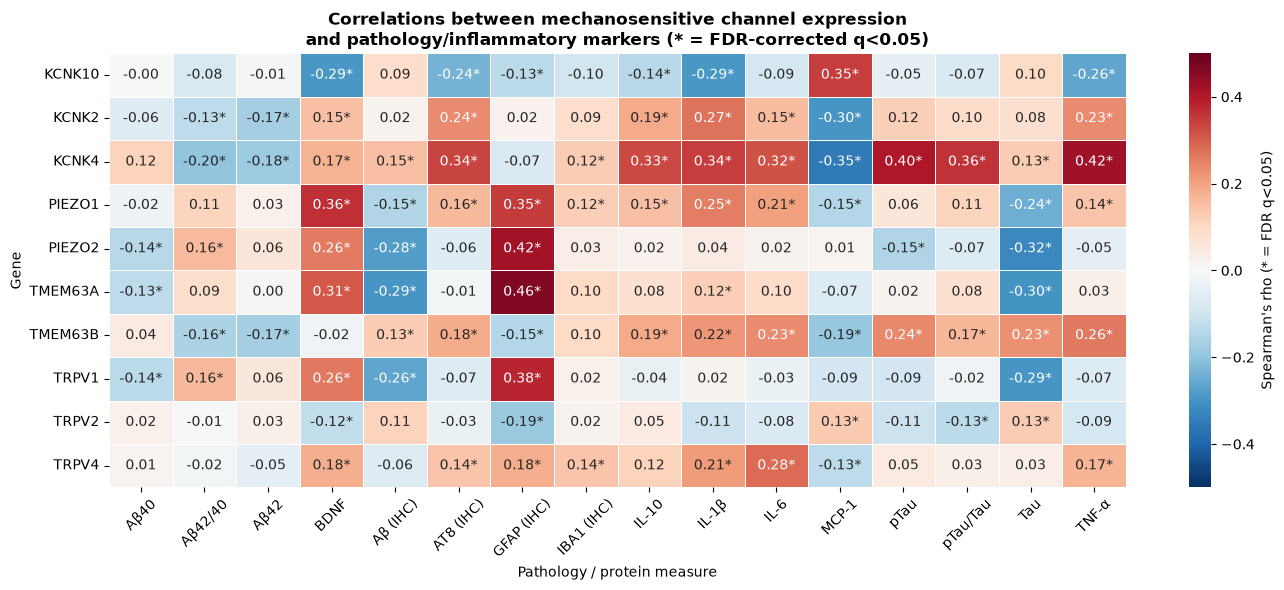

Saved.


In [5]:
# pivot into gene x measure matrix for heatmap
pivot_rho  = corr_df.pivot(index='gene', columns='measure', values='rho')
pivot_qval = corr_df.pivot(index='gene', columns='measure', values='qval')

# create annotation with * for significant correlations (qval < 0.05)
annot = pivot_rho.copy().astype(str)
for gene in pivot_rho.index:
    for measure in pivot_rho.columns:
        rho = pivot_rho.loc[gene, measure]
        q   = pivot_qval.loc[gene, measure]
        val = f"{rho:.2f}"
        if q < 0.05:
            val = f"{rho:.2f}*"
        annot.loc[gene, measure] = val

# shorten column names for readability
col_rename = {
    'tau_ng_per_mg':       'Tau',
    'ptau_ng_per_mg':      'pTau',
    'ptau_over_tau_ratio': 'pTau/Tau',
    'ihc_at8':             'AT8 (IHC)',
    'ab42_pg_per_mg':      'Aβ42',
    'ab40_pg_per_mg':      'Aβ40',
    'ab42_over_ab40_ratio':'Aβ42/40',
    'ihc_a_beta':          'Aβ (IHC)',
    'il_6_pg_per_mg':      'IL-6',
    'il_1b_pg_per_mg':     'IL-1β',
    'tnf_a_pg_per_mg':     'TNF-α',
    'mcp_1_pg_per_mg':     'MCP-1',
    'il_10_pg_per_mg':     'IL-10',
    'bdnf_pg_per_mg':      'BDNF',
    'ihc_gfap_ffpe':       'GFAP (IHC)',
    'ihc_iba1_ffpe':       'IBA1 (IHC)',
}

pivot_rho  = pivot_rho.rename(columns=col_rename)
pivot_qval = pivot_qval.rename(columns=col_rename)
annot      = annot.rename(columns=col_rename)

fig, ax = plt.subplots(figsize=(14, 6))

sns.heatmap(pivot_rho, ax=ax,
            cmap='RdBu_r', center=0,
            vmin=-0.5, vmax=0.5,
            annot=annot, fmt='',
            linewidths=0.5, linecolor='white',
            cbar_kws={'label': "Spearman's rho (* = FDR q<0.05)"})

ax.set_title('Correlations between mechanosensitive channel expression\nand pathology/inflammatory markers (* = FDR-corrected q<0.05)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Pathology / protein measure')
ax.set_ylabel('Gene')
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved.")

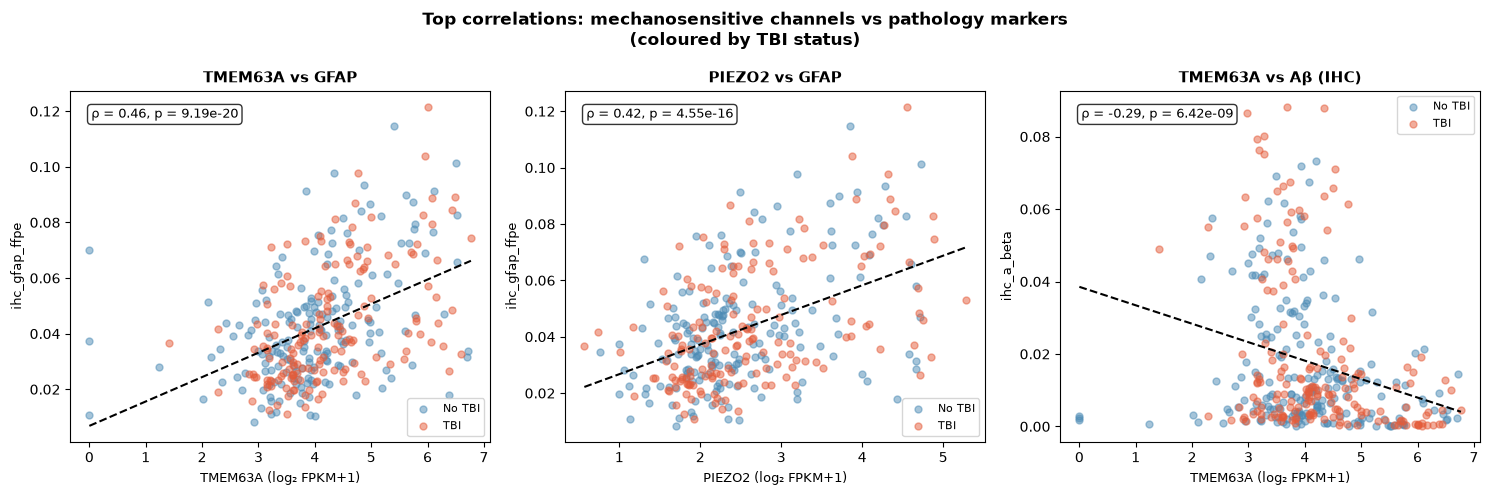

Saved.


In [7]:
# scatter plot of strongest correlation: TMEM63A vs GFAP
# coloured by TBI status to show both findings together

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

top_pairs = [
    ('TMEM63A_log2', 'ihc_gfap_ffpe', 'TMEM63A vs GFAP'),
    ('PIEZO2_log2',  'ihc_gfap_ffpe', 'PIEZO2 vs GFAP'),
    ('TMEM63A_log2', 'ihc_a_beta',    'TMEM63A vs Aβ (IHC)'),
]

tbi_colours = {0: '#4C8BB5', 1: '#E45C3A'}
tbi_labels  = {0: 'No TBI', 1: 'TBI'}

# fix age for colour coding
def parse_age(age_val):
    age_str = str(age_val).strip()
    if age_str == '100+':
        return 100.0
    elif '-' in age_str:
        parts = age_str.split('-')
        return (int(parts[0]) + int(parts[1])) / 2
    else:
        try:
            return float(age_str)
        except:
            return np.nan

merged_full['TBI'] = (merged_full['ever_tbi_w_loc'] == 'Y').astype(int)

for ax, (gene_col, path_col, title) in zip(axes, top_pairs):
    valid = merged_full[[gene_col, path_col, 'TBI']].dropna()
    
    for tbi_val, group in valid.groupby('TBI'):
        ax.scatter(group[gene_col], group[path_col],
                   color=tbi_colours[tbi_val],
                   label=tbi_labels[tbi_val],
                   alpha=0.5, s=25)
    
    # add regression line
    x = valid[gene_col]
    y = valid[path_col]
    m, b = np.polyfit(x, y, 1)
    ax.plot(x.sort_values(), m * x.sort_values() + b,
            color='black', linewidth=1.5, linestyle='--')
    
    # add rho and p-value
    rho, pval = stats.spearmanr(x, y)
    ax.text(0.05, 0.95, f"ρ = {rho:.2f}, p = {pval:.2e}",
            transform=ax.transAxes, fontsize=9,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(gene_col.replace('_log2', '') + ' (log₂ FPKM+1)', fontsize=9)
    ax.set_ylabel(path_col, fontsize=9)
    ax.legend(fontsize=8)

plt.suptitle('Top correlations: mechanosensitive channels vs pathology markers\n(coloured by TBI status)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_top_correlations_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved.")

In [9]:
# ── TBI-stratified correlations ────────────────────────────────────────────
# run same correlations separately for TBI and no-TBI donors
# then compare whether the relationship differs

merged_full['TBI'] = (merged_full['ever_tbi_w_loc'] == 'Y').astype(int)

# focus on the most biologically meaningful measures
key_measures = [
    'ihc_gfap_ffpe', 'ihc_a_beta', 'ihc_at8',
    'tau_ng_per_mg', 'il_6_pg_per_mg', 'tnf_a_pg_per_mg',
    'mcp_1_pg_per_mg', 'bdnf_pg_per_mg'
]

# focus on genes with strongest signals from earlier notebooks
key_genes = ['PIEZO2_log2', 'TMEM63A_log2', 'KCNK4_log2', 'TRPV1_log2']

strat_results = []

for tbi_val, tbi_label in [(0, 'No TBI'), (1, 'TBI')]:
    subset = merged_full[merged_full['TBI'] == tbi_val]
    
    for gene_col in key_genes:
        for measure in key_measures:
            valid = subset[[gene_col, measure]].dropna()
            if len(valid) < 15:
                continue
            rho, pval = stats.spearmanr(valid[gene_col], valid[measure])
            strat_results.append({
                'TBI_group': tbi_label,
                'gene':      gene_col.replace('_log2', ''),
                'measure':   measure,
                'rho':       rho,
                'pval':      pval,
                'n':         len(valid)
            })

strat_df = pd.DataFrame(strat_results).round(4)

# show side by side comparison
print("=== TBI-STRATIFIED CORRELATIONS ===\n")
for gene in ['PIEZO2', 'TMEM63A', 'KCNK4', 'TRPV1']:
    print(f"\n{gene}:")
    subset = strat_df[strat_df['gene'] == gene][
        ['TBI_group', 'measure', 'rho', 'pval', 'n']
    ].sort_values(['measure', 'TBI_group'])
    print(subset.to_string(index=False))

=== TBI-STRATIFIED CORRELATIONS ===


PIEZO2:
TBI_group         measure     rho   pval   n
   No TBI  bdnf_pg_per_mg  0.2504 0.0009 173
      TBI  bdnf_pg_per_mg  0.2704 0.0008 150
   No TBI      ihc_a_beta -0.2180 0.0020 198
      TBI      ihc_a_beta -0.3459 0.0000 179
   No TBI         ihc_at8 -0.0600 0.4013 198
      TBI         ihc_at8 -0.0690 0.3586 179
   No TBI   ihc_gfap_ffpe  0.3792 0.0000 181
      TBI   ihc_gfap_ffpe  0.4643 0.0000 164
   No TBI  il_6_pg_per_mg -0.0081 0.9141 178
      TBI  il_6_pg_per_mg  0.0324 0.6897 154
   No TBI mcp_1_pg_per_mg  0.0600 0.4266 178
      TBI mcp_1_pg_per_mg -0.0329 0.6852 154
   No TBI   tau_ng_per_mg -0.3898 0.0000 174
      TBI   tau_ng_per_mg -0.2467 0.0022 152
   No TBI tnf_a_pg_per_mg -0.0566 0.4529 178
      TBI tnf_a_pg_per_mg -0.0461 0.5704 154

TMEM63A:
TBI_group         measure     rho   pval   n
   No TBI  bdnf_pg_per_mg  0.2707 0.0003 173
      TBI  bdnf_pg_per_mg  0.3443 0.0000 150
   No TBI      ihc_a_beta -0.2410 0.0006 198